In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image, ImageFile
from IPython.display import display

ImageFile.LOAD_TRUNCATED_IMAGES = False

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


# Load the dataset

In [2]:
# Change this path to your actual extracted dataset location
DATASET_DIR = Path(r"C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMITES\INTERNSHIP\Project_1")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}\n"
        "Please update DATASET_DIR to your extracted dataset path."
    )

print("Dataset location:", DATASET_DIR.resolve())

print("\nFolder structure:")

for path in sorted(DATASET_DIR.rglob("*")):
    if path.is_dir():
        print("Folder: ", path.relative_to(DATASET_DIR))
    elif path.is_file():
        print("   ", path.relative_to(DATASET_DIR))

Dataset location: C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMITES\INTERNSHIP\Project_1

Folder structure:
Folder:  .ipynb_checkpoints
    .ipynb_checkpoints\PRCP-1001-RiceLeaf-disease-detection-checkpoint.ipynb
    .ipynb_checkpoints\rice_leaf_class_names-checkpoint.json
    .ipynb_checkpoints\Untitled-checkpoint.ipynb
    PRCP-1001-RiceLeaf-disease-detection.ipynb
    rice_leaf_class_names.json
    rice_leaf_cnn.keras
Folder:  RiceLeaf
Folder:  RiceLeaf\Bacterial leaf blight
    RiceLeaf\Bacterial leaf blight\DSC_0365.JPG
    RiceLeaf\Bacterial leaf blight\DSC_0366.jpg
    RiceLeaf\Bacterial leaf blight\DSC_0367.JPG
    RiceLeaf\Bacterial leaf blight\DSC_0370.jpg
    RiceLeaf\Bacterial leaf blight\DSC_0372.JPG
    RiceLeaf\Bacterial leaf blight\DSC_0373.JPG
    RiceLeaf\Bacterial leaf blight\DSC_0374.JPG
    RiceLeaf\Bacterial leaf blight\DSC_0375.JPG
    RiceLeaf\Bacterial leaf blight\DSC_0376.JPG
    RiceLeaf\Bacterial leaf blight\DSC_0377.JPG
    RiceLeaf\Bacterial leaf blight\DS

# Indentifying Disease classes and image count

In [3]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}

class_folders = []

for folder in DATASET_DIR.rglob("*"):
    if folder.is_dir():
        image_files = [
            file for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        ]

        if image_files:
            class_folders.append(folder)

class_folders = [
    folder for folder in class_folders
    if not any(
        child != folder and folder in child.parents
        for child in class_folders
    )
]

class_folders = sorted(class_folders)

if not class_folders:
    raise ValueError(
        "No class folders containing images were found. "
        "Check DATASET_DIR and the extracted dataset structure."
    )

class_counts = []

for folder in class_folders:
    files = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts.append({
        "Disease": folder.name,
        "Image_Count": len(files)
    })

class_df = pd.DataFrame(class_counts)

display(class_df)

print("Total classes:", len(class_df))
print("Total images:", class_df["Image_Count"].sum())

,Disease,Image_Count
0,Bacterial leaf blight,40
1,Brown spot,40
2,Leaf smut,39


Total classes: 3
Total images: 119


# Visualie the Class Distribution

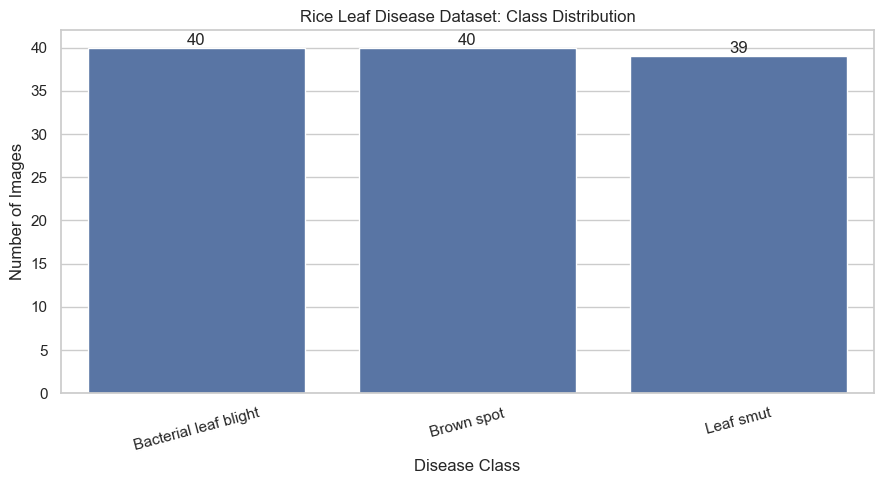

In [4]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=class_df,
    x="Disease",
    y="Image_Count"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Rice Leaf Disease Dataset: Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

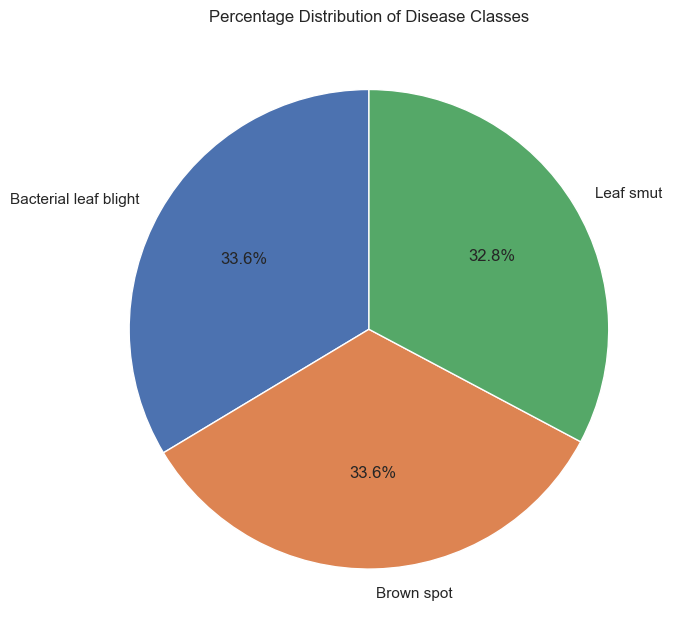

In [5]:
plt.figure(figsize=(7, 7))

plt.pie(
    class_df["Image_Count"],
    labels=class_df["Disease"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Disease Classes")
plt.tight_layout()
plt.show()

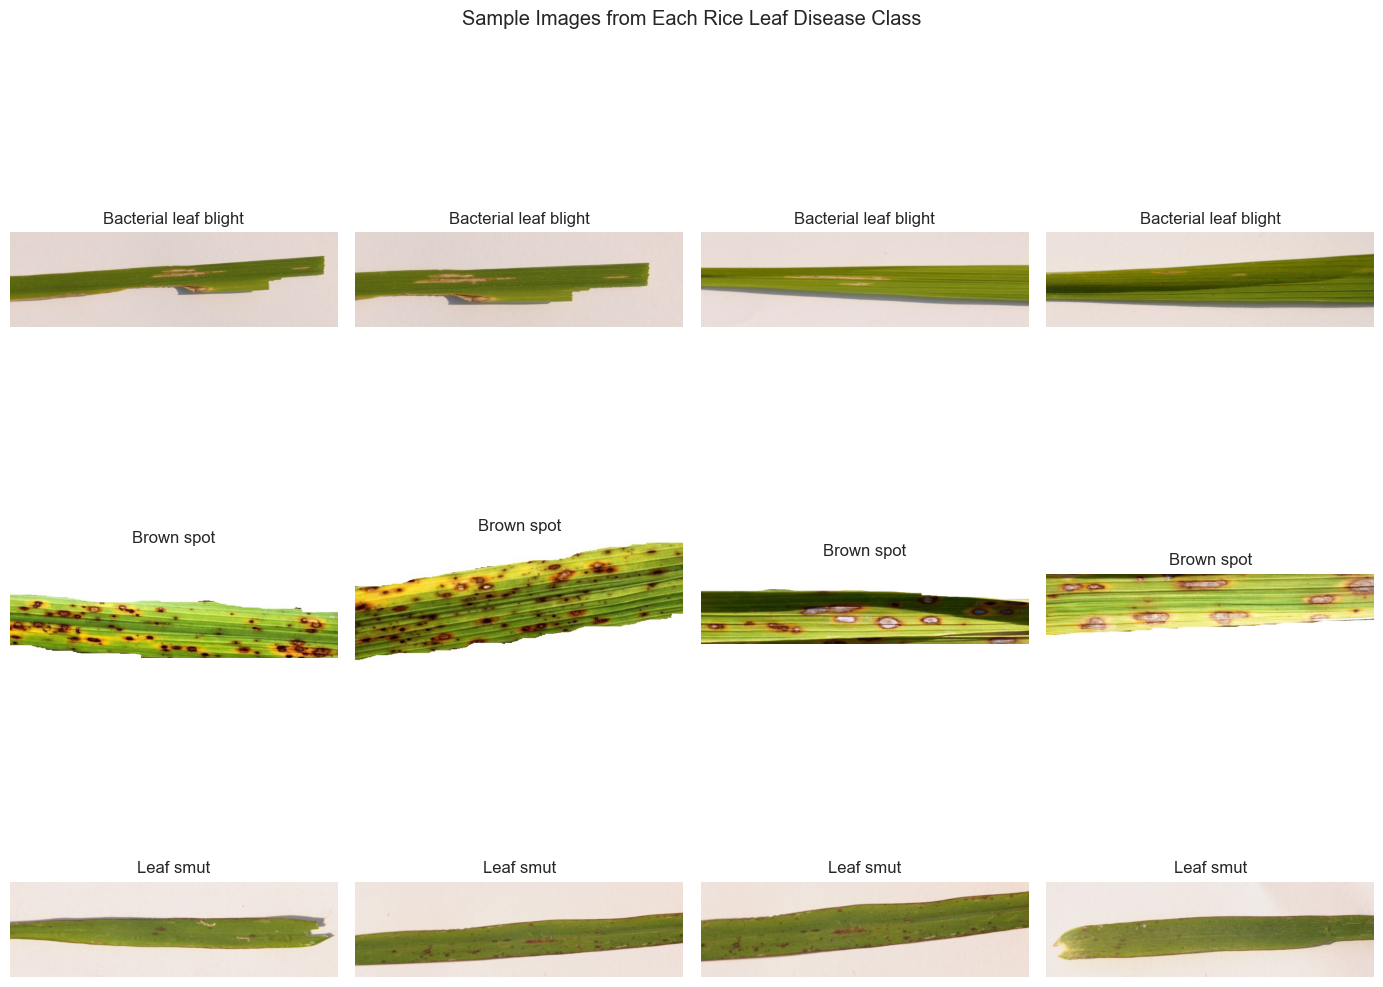

In [6]:
fig, axes = plt.subplots(len(class_folders), 4, figsize=(14, 4 * len(class_folders)))
axes = np.array(axes).reshape(len(class_folders), 4)

for i, folder in enumerate(class_folders):
    images = [f for f in sorted(folder.iterdir()) if f.suffix.lower() in IMAGE_EXTENSIONS][:4]

    for j, ax in enumerate(axes[i]):
        ax.axis("off")
        if j < len(images):
            ax.imshow(Image.open(images[j]).convert("RGB"))
            ax.set_title(folder.name)

plt.suptitle("Sample Images from Each Rice Leaf Disease Class")
plt.tight_layout()
plt.show()

In [7]:
image_records = []

for folder in class_folders:
    image_files = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for file in image_files:
        record = {
            "Disease": folder.name,
            "Filename": file.name,
            "Path": str(file),
            "Extension": file.suffix.lower()
        }

        try:
            with Image.open(file) as img:
                record["Format"] = img.format
                record["Width"] = img.width
                record["Height"] = img.height
                record["Color_Mode"] = img.mode
                record["Aspect_Ratio"] = round(
                    img.width / img.height, 3
                )
                record["File_Size_KB"] = round(
                    file.stat().st_size / 1024, 2
                )

                img.verify()
                record["Status"] = "Valid"

        except Exception as e:
            record["Format"] = None
            record["Width"] = None
            record["Height"] = None
            record["Color_Mode"] = None
            record["Aspect_Ratio"] = None
            record["File_Size_KB"] = (
                round(file.stat().st_size / 1024, 2)
                if file.exists() else None
            )
            record["Status"] = f"Error: {e}"

        image_records.append(record)

image_df = pd.DataFrame(image_records)

display(image_df.head(10))

print("Total image files inspected:", len(image_df))
print("\nImage status:")
display(image_df["Status"].value_counts().to_frame("Count"))

print("\nImage formats:")
display(image_df["Format"].value_counts(dropna=False).to_frame("Count"))

print("\nColor modes:")
display(image_df["Color_Mode"].value_counts(dropna=False).to_frame("Count"))

,Disease,Filename,Path,Extension,Format,Width,Height,Color_Mode,Aspect_Ratio,File_Size_KB,Status
0,Bacterial leaf blight,DSC_0365.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,456.16,Valid
1,Bacterial leaf blight,DSC_0366.jpg,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,408.13,Valid
2,Bacterial leaf blight,DSC_0367.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,442.02,Valid
3,Bacterial leaf blight,DSC_0370.jpg,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,418.68,Valid
4,Bacterial leaf blight,DSC_0372.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,470.20,Valid
5,Bacterial leaf blight,DSC_0373.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,384.53,Valid
6,Bacterial leaf blight,DSC_0374.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,485.56,Valid
7,Bacterial leaf blight,DSC_0375.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,408.03,Valid
8,Bacterial leaf blight,DSC_0376.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,394.24,Valid
9,Bacterial leaf blight,DSC_0377.JPG,C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMI...,.jpg,JPEG,3081,897,RGB,3.435,379.45,Valid


Total image files inspected: 119

Image status:


,Count
Status,
Valid,119



Image formats:


,Count
Format,
JPEG,119



Color modes:


,Count
Color_Mode,
RGB,119


# Analyze image size

In [8]:
valid_images = image_df[
    image_df["Status"].eq("Valid")
].copy()

print("Unique image dimensions:")

display(
    valid_images.groupby(["Width", "Height"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\nDimension statistics:")

display(
    valid_images[["Width", "Height", "Aspect_Ratio",
                  "File_Size_KB"]].describe()
)


Unique image dimensions:


,Width,Height,Count
33,3081,897,85
0,250,200,2
2,296,88,1
3,301,71,1
32,1530,371,1
31,1504,323,1
30,1480,279,1
29,1200,900,1
28,948,233,1
27,948,211,1



Dimension statistics:


,Width,Height,Aspect_Ratio,File_Size_KB
count,119.000000,119.000000,119.000000,119.000000
mean,2383.638655,707.739496,3.325395,307.771261
std,1123.528972,311.657582,0.646498,172.701350
min,250.000000,71.000000,1.250000,22.760000
25%,1074.000000,377.000000,3.435000,102.660000
50%,3081.000000,897.000000,3.435000,379.450000
75%,3081.000000,897.000000,3.435000,426.875000
max,3081.000000,900.000000,5.305000,643.400000


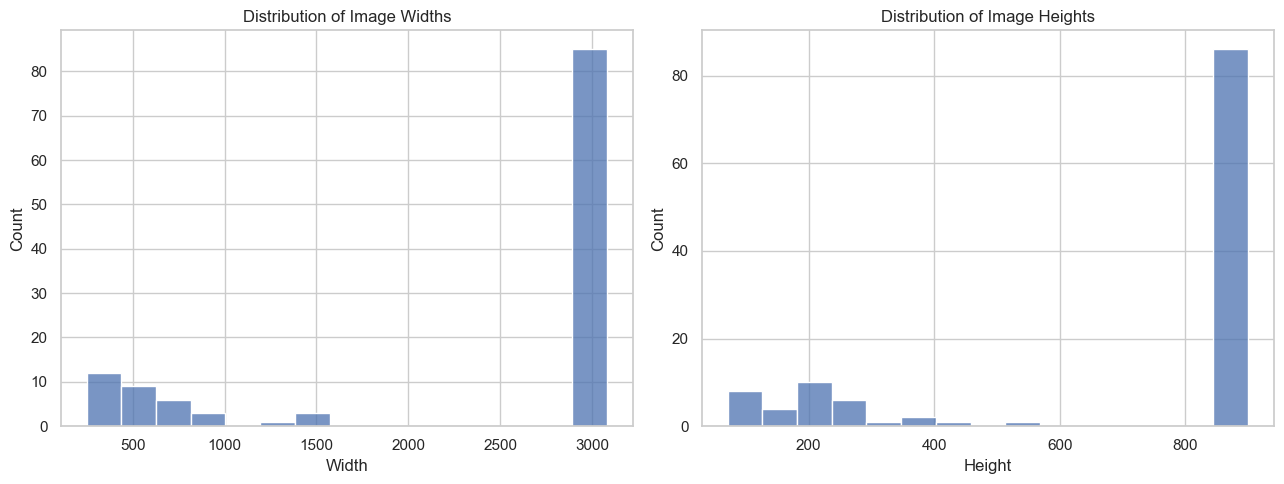

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=valid_images,
    x="Width",
    bins=15,
    ax=axes[0]
)
axes[0].set_title("Distribution of Image Widths")

sns.histplot(
    data=valid_images,
    x="Height",
    bins=15,
    ax=axes[1]
)
axes[1].set_title("Distribution of Image Heights")

plt.tight_layout()
plt.show()

# Check image quality and possible data issues


In [10]:
invalid_images = image_df[
    image_df["Status"] != "Valid"
]

print("Invalid or unreadable images:", len(invalid_images))

if len(invalid_images) > 0:
    display(invalid_images[["Disease", "Filename", "Status"]])
else:
    print("All inspected image files passed the validation check.")
    

Invalid or unreadable images: 0
All inspected image files passed the validation check.


# Check for very small images


In [11]:
small_images = valid_images[
    (valid_images["Width"] < 64)
    | (valid_images["Height"] < 64)
]

print("Images smaller than 64 pixels in either dimension:",
      len(small_images))

display(
    small_images[["Disease", "Filename", "Width", "Height"]]
)

Images smaller than 64 pixels in either dimension: 0


,Disease,Filename,Width,Height


# Check for exact duplication image 

In [12]:
import hashlib

hash_records = []

for folder in class_folders:
    for file in folder.iterdir():
        if (
            file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        ):
            try:
                digest = hashlib.sha256(file.read_bytes()).hexdigest()

                hash_records.append({
                    "Disease": folder.name,
                    "Filename": file.name,
                    "Path": str(file),
                    "Hash": digest
                })
            except OSError:
                pass

hash_df = pd.DataFrame(hash_records)

duplicate_images = hash_df[
    hash_df.duplicated("Hash", keep=False)
].sort_values("Hash")

print("Files involved in exact duplicate groups:",
      len(duplicate_images))

display(duplicate_images)

Files involved in exact duplicate groups: 0


,Disease,Filename,Path,Hash


# Generate a summury of EDA findings 

In [13]:
total_images = len(image_df)
total_classes = len(class_folders)
valid_count = len(valid_images)
invalid_count = len(invalid_images)

print("RICE LEAF DISEASE DETECTION: EDA SUMMARY")
print(" ")
print(f"Total image files found: {total_images}")
print(f"Total disease classes found: {total_classes}")
print(f"Valid images: {valid_count}")
print(f"Invalid images: {invalid_count}")

print("\nClass distribution:")
for _, row in class_df.iterrows():
    percentage = (
        row["Image_Count"] / total_images * 100
        if total_images else 0
    )
    print(
        f'{row["Disease"]}: {row["Image_Count"]} images '
        f'({percentage:.1f}%)'
    )

if not class_df.empty:
    print("\nClass balance:")
    if class_df["Image_Count"].nunique() == 1:
        print("All classes have equal image counts.")
    else:
        print("The class counts are unequal.")

if not valid_images.empty:
    print("\nImage properties:")
    print("Image formats:",
          valid_images["Format"].value_counts().to_dict())
    print("Unique dimensions:",
          valid_images[["Width", "Height"]]
          .drop_duplicates().shape[0])

print("\nExact duplicate files detected:",
      len(duplicate_images))

RICE LEAF DISEASE DETECTION: EDA SUMMARY
 
Total image files found: 119
Total disease classes found: 3
Valid images: 119
Invalid images: 0

Class distribution:
Bacterial leaf blight: 40 images (33.6%)
Brown spot: 40 images (33.6%)
Leaf smut: 39 images (32.8%)

Class balance:
The class counts are unequal.

Image properties:
Image formats: {'JPEG': 119}
Unique dimensions: 34

Exact duplicate files detected: 0


# Task 1: Exploratory Data Analysis — Rice Leaf Disease Detection

## 1. Objective

The main objective of this task is to understand the rice leaf disease dataset before building a classification model.

I checked the dataset structure, number of images in each class, sample images, image sizes, file formats, and possible data quality problems.

This analysis helped me understand the dataset and prepare it for model training.

## 2. Dataset Overview

According to the project document, the dataset contains 120 JPG images from three rice leaf disease categories: Leaf smut, Brown spot, and Bacterial leaf blight.

Each category contains 40 images.

I checked the extracted dataset to verify the number of images in each category.

## 3. Class Distribution

I checked the number of images in each disease category using a frequency table, bar chart, and pie chart.

These visualizations helped me understand the distribution of images in the dataset.

The actual class counts and percentages will be added based on the results from my notebook.

## 4. Sample Image Analysis

I displayed sample images from all three disease categories to understand their appearance.

I observed the leaf colors, disease spots, discoloration, image backgrounds, and lighting conditions.

This helped me understand the visual differences between the disease categories.

The actual observations will be added based on the images displayed in the notebook.

## 5. Image Properties

I checked the image dimensions, file formats, color modes, aspect ratios, and file sizes.

This helped me understand whether the images were similar or different in their properties.

I also identified the preprocessing steps required before training the CNN model.

The actual image properties and any differences will be added based on the notebook results.

## 6. Data Quality Assessment

I checked the dataset for unreadable images, very small images, and duplicate images.

This helped me identify possible data quality problems that could affect model training.

The number of affected images and the steps taken to handle them will be added based on the actual results.

## 7. Key Findings

From this analysis, I understood the distribution of images across the three disease categories.

I also observed the visual appearance of different rice leaf diseases and checked the consistency of the image properties.

The final findings will be added based on the actual results from the notebook.

## 8. Conclusion

In this task, I performed exploratory data analysis on the rice leaf disease dataset.

I learned how to check the dataset structure, analyze class distribution, display sample images, inspect image properties, and identify possible data quality issues.

This analysis helped me understand the dataset and prepare it for the next step.

In the next stage, I will preprocess the images, divide the dataset into training, validation, and test sets, and develop a CNN model for rice leaf disease classification.

# Task 2 - Creating Model

In [14]:
%pip install tensorflow scikit-learn pillow matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [15]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: False


## Load the images and labels

In [16]:
DATASET_DIR = Path(
    r"C:\Users\SHEKHAR SUMAN\OneDrive\Desktop\DATAMITES\INTERNSHIP\Project_1\RiceLeaf"
)

IMAGE_SIZE = (128, 128)
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_DIR}")

# Identify leaf folders containing images, even if nested.
candidate_folders = [
    folder for folder in DATASET_DIR.rglob("*")
    if folder.is_dir()
    and any(
        file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        for file in folder.iterdir()
    )
]

class_folders = [
    folder for folder in candidate_folders
    if not any(
        other != folder and folder in other.parents
        for other in candidate_folders
    )
]

class_folders = sorted(class_folders)

if len(class_folders) != 3:
    raise ValueError(
        f"Expected 3 disease-class folders, found {len(class_folders)}. "
        "Inspect the dataset structure and select the correct class folders."
    )

class_names = [folder.name for folder in class_folders]
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

image_paths = []
labels = []

for folder in class_folders:
    for file in sorted(folder.iterdir()):
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS:
            try:
                with Image.open(file) as img:
                    img.verify()

                image_paths.append(str(file))
                labels.append(class_to_index[folder.name])

            except Exception as e:
                print(f"Skipping unreadable image: {file.name} — {e}")

image_paths = np.array(image_paths)
labels = np.array(labels, dtype=np.int32)

print("Classes:", class_names)
print("Total valid images:", len(image_paths))

print("\nClass counts:")
for class_name, index in class_to_index.items():
    print(f"{class_name}: {np.sum(labels == index)}")

if len(np.unique(labels)) != 3:
    raise ValueError("All three disease classes must contain valid images.")

Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
Total valid images: 119

Class counts:
Bacterial leaf blight: 40
Brown spot: 40
Leaf smut: 39


## Resize images and normalize pixel values

In [17]:
X = []

for path in image_paths:
    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize(IMAGE_SIZE)
        X.append(np.asarray(img, dtype=np.float32) / 255.0)

X = np.array(X, dtype=np.float32)
y = labels

print("Image array shape:", X.shape)
print("Label array shape:", y.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Image array shape: (119, 128, 128, 3)
Label array shape: (119,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Split the dataset

In [18]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y )

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTraining distribution:")
print(pd.Series(y_train).map(dict(enumerate(class_names))).value_counts())

print("\nValidation distribution:")
print(pd.Series(y_val).map(dict(enumerate(class_names))).value_counts())

print("\nTesting distribution:")
print(pd.Series(y_test).map(dict(enumerate(class_names))).value_counts())

Training images: 83
Validation images: 18
Testing images: 18

Training distribution:
Brown spot               28
Bacterial leaf blight    28
Leaf smut                27
Name: count, dtype: int64

Validation distribution:
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64

Testing distribution:
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64


## Build the CNN model

In [19]:
tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

## Train the model

In [20]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=8,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - accuracy: 0.2651 - loss: 1.1063 - val_accuracy: 0.3333 - val_loss: 1.0958 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.3855 - loss: 1.0979 - val_accuracy: 0.6111 - val_loss: 1.0940 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.3855 - loss: 1.0959 - val_accuracy: 0.4444 - val_loss: 1.0904 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.3614 - loss: 1.0937 - val_accuracy: 0.5000 - val_loss: 1.0823 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.4217 - loss: 1.0876 - val_accuracy: 0.4444 - val_loss: 1.0663 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.4699 - loss: 1.0707 - val_accuracy: 0.6667 - val_loss: 1.0283 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.5301 - loss: 1.0415 - val_acc

## Plot traning and validation performance 

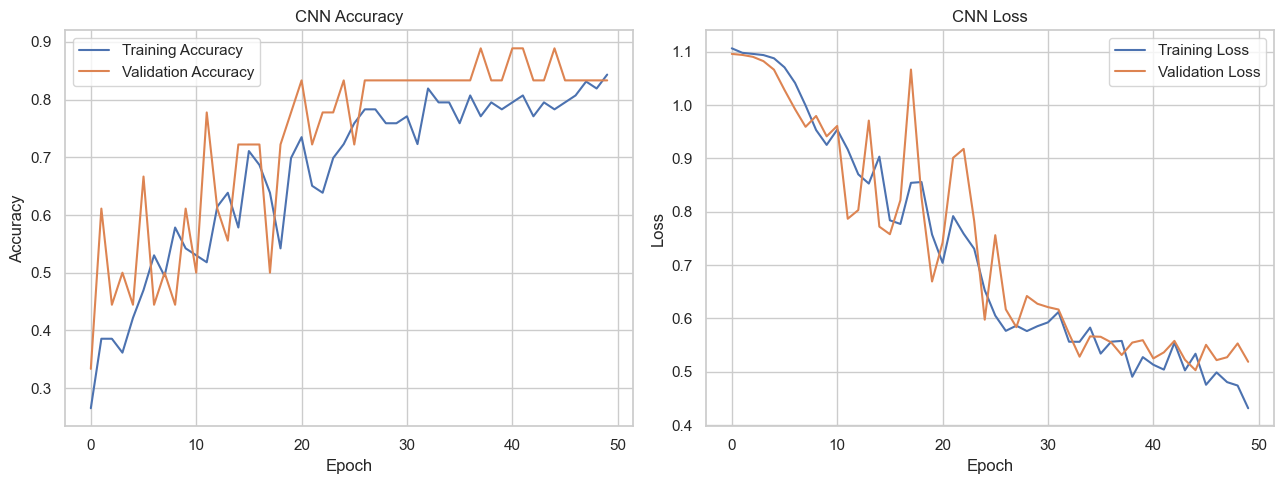

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluate model on test images

In [22]:
test_probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probabilities, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics_df.round(4))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

,Metric,Score
0,Accuracy,0.7222
1,Macro Precision,0.7417
2,Macro Recall,0.7222
3,Macro F1-score,0.7229



Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      0.67      0.73         6
           Brown spot       0.80      0.67      0.73         6
            Leaf smut       0.62      0.83      0.71         6

             accuracy                           0.72        18
            macro avg       0.74      0.72      0.72        18
         weighted avg       0.74      0.72      0.72        18



## Plot Confusion matrix 

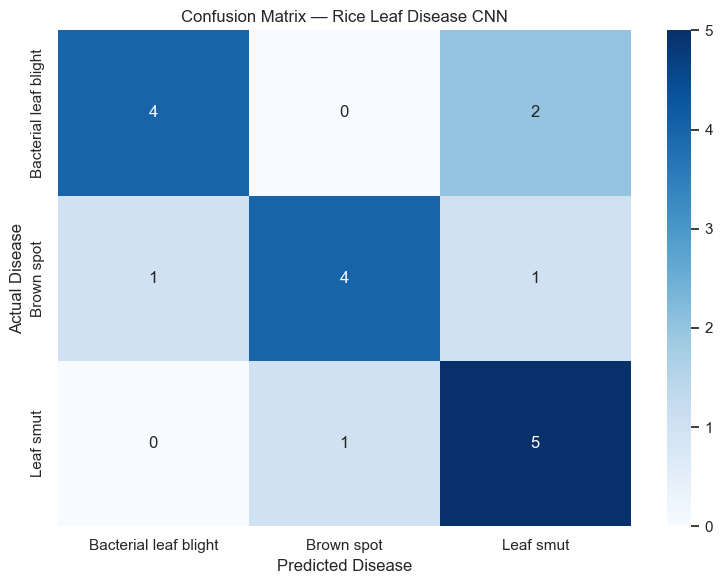

In [23]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix — Rice Leaf Disease CNN")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.tight_layout()
plt.show()

## Predict the disease from a new images

In [24]:
def predict_disease(image_path):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize(IMAGE_SIZE)
        image_array = np.asarray(img, dtype=np.float32) / 255.0

    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])

    plt.figure(figsize=(5, 5))
    plt.imshow(image_array[0])
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Model confidence: {confidence:.2%}"
    )
    plt.show()

    probability_df = pd.DataFrame({
        "Disease": class_names,
        "Probability": probabilities
    }).sort_values("Probability", ascending=False)

    display(probability_df.style.format({"Probability": "{:.2%}"}))

    return predicted_class, confidence

## Run this cell with the actual path to your new image

Exists: True


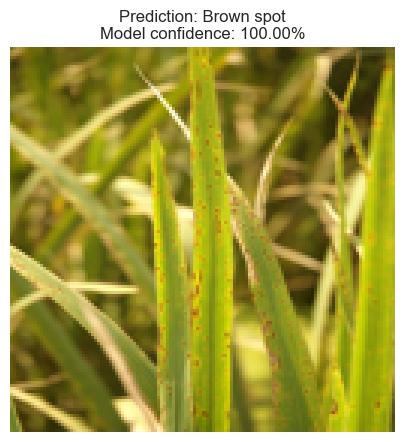

,Disease,Probability
1,Brown spot,100.00%
0,Bacterial leaf blight,0.00%
2,Leaf smut,0.00%


Predicted disease: Brown spot
Model confidence: 100.00%


In [25]:
new_image_path = Path(
    r"E:\PICTURE\Screenshots\new-image.png"
)
# E:\PICTURE\Screenshots\rice.png
# E:\PICTURE\Screenshots\new-image.png
# E:\PICTURE\Screenshots\Screenshot 2026-10-27 180753.png
print("Exists:", new_image_path.is_file())

predicted_disease, confidence = predict_disease(str(new_image_path))

print("Predicted disease:", predicted_disease)
print(f"Model confidence: {confidence:.2%}")

In [26]:
model.save("rice_leaf_cnn.keras")

with open("rice_leaf_class_names.json", "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=4)

print("Model saved as rice_leaf_cnn.keras")
print("Class labels saved as rice_leaf_class_names.json")

Model saved as rice_leaf_cnn.keras
Class labels saved as rice_leaf_class_names.json


# Task 2: Rice Leaf Disease Classification Using CNN

## 1. Objective

The main objective of this task is to build a CNN model to identify rice leaf diseases from images.

The model classifies rice leaves into three categories: Leaf smut, Brown spot, and Bacterial leaf blight, based on the dataset labels.

## 2. Data Preprocessing

First, I converted all images into RGB format and resized them to 128 × 128 pixels.

After that, I normalized the pixel values between 0 and 1 to make the data suitable for model training.

I divided the dataset into training, validation, and testing sets using stratified sampling. This helped maintain the class distribution in each set.

## 3. Model Architecture

I created a CNN model using convolutional layers and max-pooling layers to extract important features from the images.

I also used global average pooling, a dense layer, and dropout to help the model learn and reduce overfitting.

The final softmax layer was used to predict the probabilities for all three disease categories.

I compiled the model using the Adam optimizer and sparse categorical cross-entropy loss.

## 4. Model Training

I trained the CNN model using the training dataset and checked its performance using validation loss and validation accuracy.

I used early stopping to stop training when the model was not improving. I also used learning-rate reduction to help the model learn better.

During training, I observed the training and validation performance to understand how the model was learning.

The actual training time, stopping epoch, and learning curve observations will be added based on the training results.

## 5. Model Evaluation

After training, I tested the model using the test dataset.

I used accuracy, macro precision, macro recall, macro F1-score, and a confusion matrix to check the model performance.

The actual evaluation results will be added from the model evaluation output.

## 6. Prediction on a New Image

I provided a new rice leaf image to the trained model for prediction.

I processed the image using the same preprocessing steps used during training.

The model predicted the disease category and returned the probability for each class.

This helped me understand how the trained model works with a new image.

## 7. Limitations

The dataset contains a limited number of images, so the model may not perform well in every situation.

There is also a chance of overfitting because the model may learn patterns from the training images instead of learning general features.

The model needs further testing with images from different farms, lighting conditions, and cameras.

## 8. Conclusion

In this task, I developed a CNN model to classify rice leaf diseases.

I learned how to preprocess images, build a CNN model, train it, evaluate its performance, and predict the disease from a new image.

The actual test results will help me understand how well the model performs. Further testing with more independent images is required before using it in real applications.

# Task 3  Data Augmentation Techniques for Rice Leaf Disease 

In [27]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

# Experiment A: No augmentation
no_augmentation = None

# Experiment B: Geometric augmentation
geometric_augmentation = models.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08
    )
], name="geometric_augmentation")

# Experiment C: Geometric + brightness augmentation
combined_augmentation = models.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08
    ),
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0.0, 1.0)
    )
], name="combined_augmentation")

print("Augmentation pipelines created successfully.")

Augmentation pipelines created successfully.


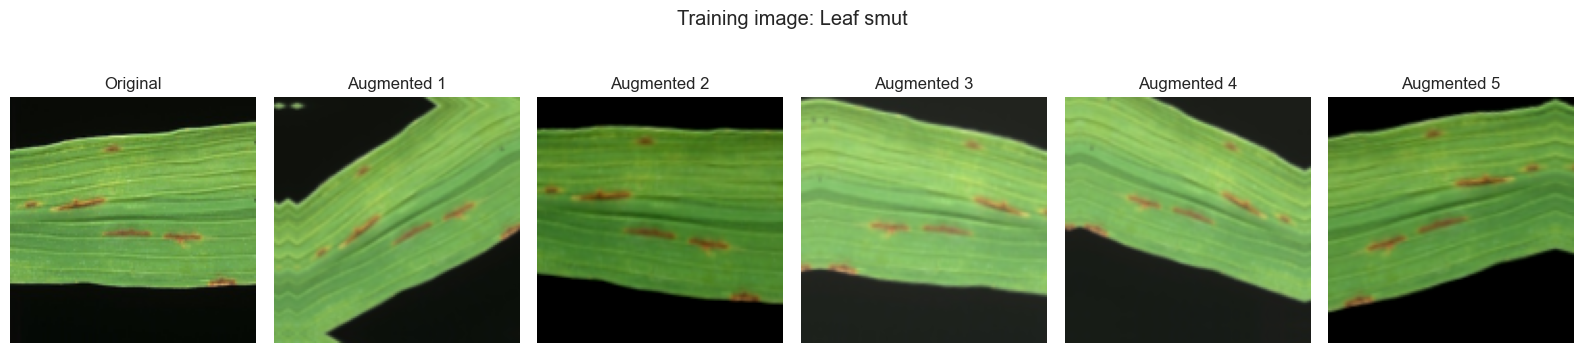

In [28]:
sample_index = 0
sample_image = X_train[sample_index]

fig, axes = plt.subplots(1, 6, figsize=(16, 4))

axes[0].imshow(sample_image)
axes[0].set_title("Original")

for i in range(1, 6):
    augmented_image = combined_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0].numpy()

    axes[i].imshow(np.clip(augmented_image, 0, 1))
    axes[i].set_title(f"Augmented {i}")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Training image: {class_names[int(y_train[sample_index])]}"
)
plt.tight_layout()
plt.show()

In [29]:
def build_cnn(augmentation=None):
    model_layers = [
        layers.Input(shape=(128, 128, 3))
    ]

    if augmentation is not None:
        model_layers.append(augmentation)

    model_layers.extend([
        layers.Conv2D(
            32, (3, 3), activation="relu", padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3), activation="relu", padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            128, (3, 3), activation="relu", padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(len(class_names), activation="softmax")
    ])

    model = models.Sequential(model_layers)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def get_callbacks():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=0
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=0
        )
    ]

In [30]:
experiments = {
    "Baseline (No Augmentation)": None,
    "Geometric Augmentation": geometric_augmentation,
    "Geometric + Brightness": combined_augmentation
}

trained_models = {}
training_histories = {}
comparison_results = []

for experiment_name, augmentation in experiments.items():

    print(f"\nTraining: {experiment_name}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    experiment_model = build_cnn(augmentation)

    history = experiment_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=8,
        callbacks=get_callbacks(),
        verbose=1
    )

    trained_models[experiment_name] = experiment_model
    training_histories[experiment_name] = history

    best_epoch = np.argmin(history.history["val_loss"]) + 1
    best_val_accuracy = max(history.history["val_accuracy"])

    comparison_results.append({
        "Experiment": experiment_name,
        "Best Epoch": best_epoch,
        "Best Validation Accuracy": best_val_accuracy,
        "Minimum Validation Loss": min(history.history["val_loss"])
    })

validation_results = pd.DataFrame(comparison_results)

display(
    validation_results.style.format({
        "Best Validation Accuracy": "{:.2%}",
        "Minimum Validation Loss": "{:.4f}"
    })
)


Training: Baseline (No Augmentation)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.2651 - loss: 1.1063 - val_accuracy: 0.3333 - val_loss: 1.0958 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.3855 - loss: 1.0979 - val_accuracy: 0.6111 - val_loss: 1.0940 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.3855 - loss: 1.0959 - val_accuracy: 0.4444 - val_loss: 1.0904 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.3614 - loss: 1.0937 - val_accuracy: 0.5000 - val_loss: 1.0823 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.4217 - loss: 1.0876 - val_accuracy: 0.4444 - val_loss: 1.0663 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.4699 - loss: 1.0707 - val_accuracy: 0.6667 - val_loss: 1.0283 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - ac

,Experiment,Best Epoch,Best Validation Accuracy,Minimum Validation Loss
0,Baseline (No Augmentation),45,88.89%,0.5029
1,Geometric Augmentation,27,88.89%,0.6432
2,Geometric + Brightness,23,83.33%,0.7795


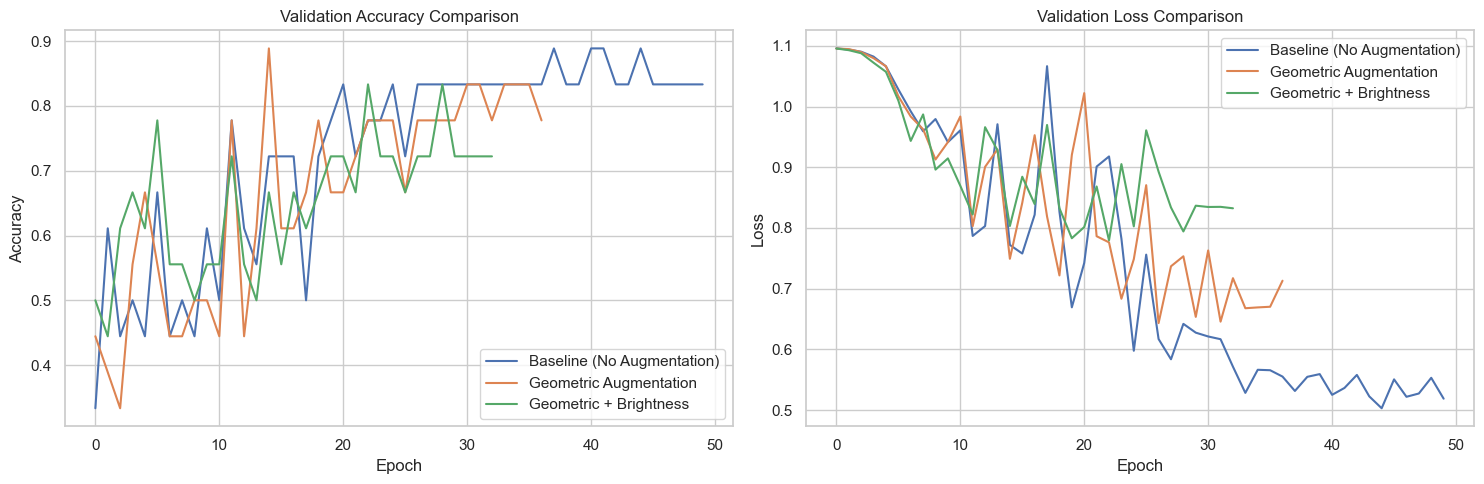

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, history in training_histories.items():
    axes[0].plot(
        history.history["val_accuracy"],
        label=name
    )
    axes[1].plot(
        history.history["val_loss"],
        label=name
    )

axes[0].set_title("Validation Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].set_title("Validation Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [32]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

test_results = []
test_predictions = {}

for name, experiment_model in trained_models.items():

    probabilities = experiment_model.predict(
        X_test,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)
    test_predictions[name] = predictions

    test_results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

test_comparison = pd.DataFrame(test_results)

display(
    test_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1-score": "{:.2%}"
    })
)

,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Baseline (No Augmentation),72.22%,74.17%,72.22%,72.29%
1,Geometric Augmentation,55.56%,55.19%,55.56%,53.74%
2,Geometric + Brightness,55.56%,54.60%,55.56%,54.86%


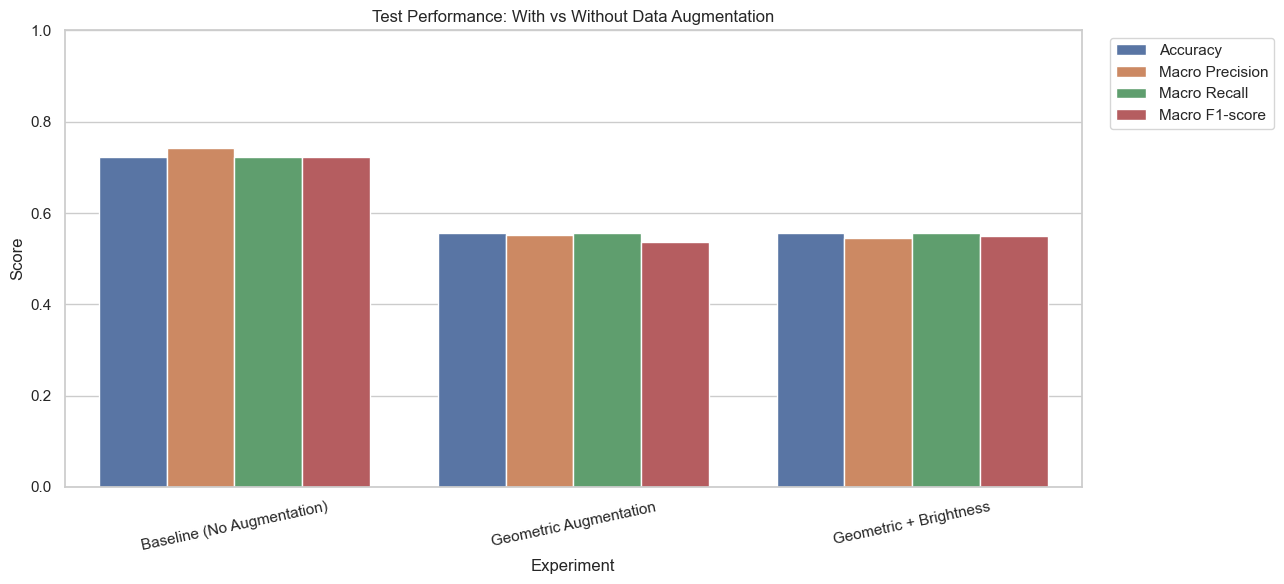

In [33]:
plot_df = test_comparison.melt(
    id_vars="Experiment",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_df,
    x="Experiment",
    y="Score",
    hue="Metric"
)

plt.title("Test Performance: With vs Without Data Augmentation")
plt.ylabel("Score")
plt.xlabel("Experiment")
plt.ylim(0, 1)
plt.xticks(rotation=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

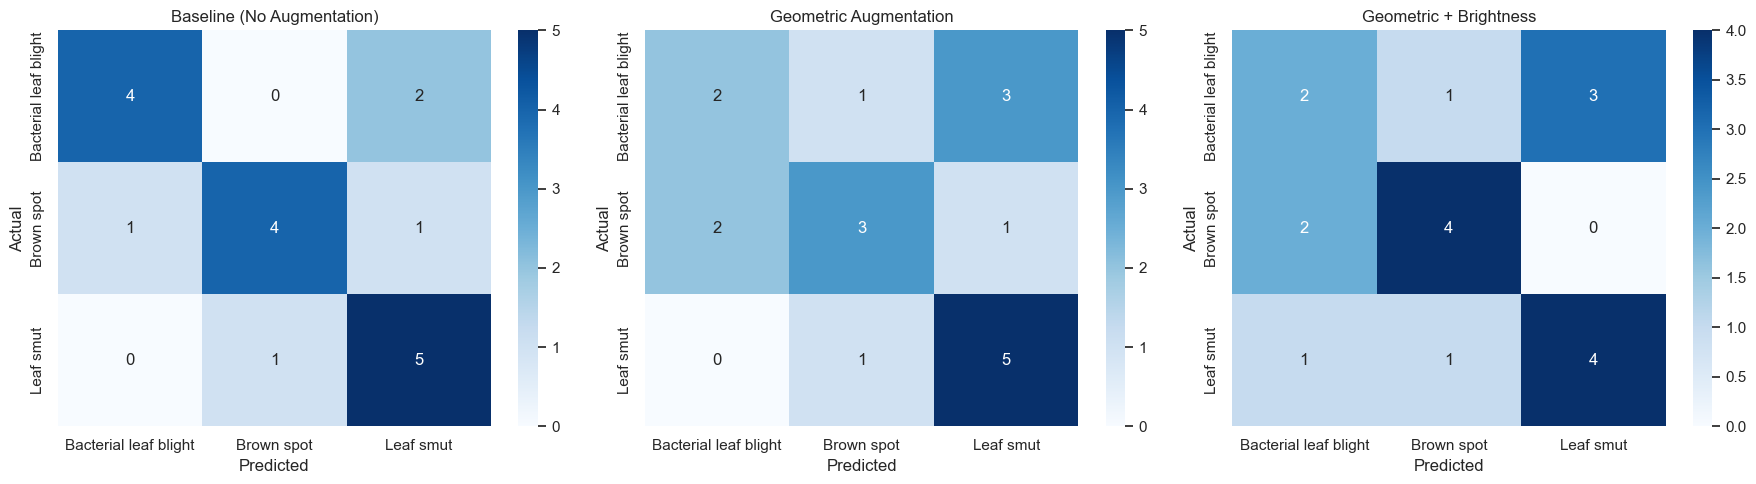

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, test_predictions.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(len(class_names))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [35]:
from sklearn.metrics import f1_score

selection_results = []

for name, experiment_model in trained_models.items():
    val_probabilities = experiment_model.predict(X_val, verbose=0)
    val_predictions = np.argmax(val_probabilities, axis=1)

    selection_results.append({
        "Experiment": name,
        "Validation Macro F1": f1_score(
            y_val,
            val_predictions,
            labels=np.arange(len(class_names)),
            average="macro",
            zero_division=0
        )
    })

selection_df = pd.DataFrame(selection_results)

display(
    selection_df.sort_values(
        "Validation Macro F1", ascending=False
    ).style.format({
        "Validation Macro F1": "{:.4f}"
    })
)

best_name = selection_df.sort_values(
    "Validation Macro F1", ascending=False
).iloc[0]["Experiment"]

best_model = trained_models[best_name]

print("Recommended experiment:", best_name)

best_model.save("rice_leaf_best_augmented_model.keras")
print("Recommended model saved successfully.")

,Experiment,Validation Macro F1
0,Baseline (No Augmentation),0.8885
2,Geometric + Brightness,0.8372
1,Geometric Augmentation,0.7825


Recommended experiment: Baseline (No Augmentation)
Recommended model saved successfully.


# Task 3: Analysis of Data Augmentation Techniques

## 1. Objective

The main objective of this experiment is to check whether data augmentation can improve the performance of a CNN model used for rice leaf disease classification.

I wanted to understand whether changing the training images in different ways can help the model learn better and predict diseases correctly on new images.

## 2. Techniques Investigated

I performed three experiments:

- **Experiment A — Baseline:** In this experiment, the CNN model was trained without using data augmentation.
- **Experiment B — Geometric Augmentation:** I used random rotation, horizontal flipping, zooming, and shifting of images.
- **Experiment C — Combined Augmentation:** In this experiment, I used geometric transformations along with random brightness changes.

The same dataset split and CNN architecture were used in all three experiments to make a fair comparison.

## 3. Experimental Methodology

All images were resized to 128 × 128 pixels and normalized between 0 and 1.

Data augmentation was applied only to the training images. Validation and test images were kept unchanged.

I used early stopping and monitored the validation loss during training to avoid unnecessary training and reduce overfitting.

After training, I compared all three models using accuracy, macro precision, macro recall, macro F1-score, and confusion matrices.

## 4. Results

The actual results from the validation and test comparison tables will be added in this section.

I will compare the performance of all three experiments and check which model achieved the best validation macro F1-score.

I will also check whether the model performed similarly on the test dataset. This will help me understand whether the model can correctly classify new images.

## 5. Interpretation

The results will help me understand whether data augmentation improved the model performance.

I will check whether the augmented models performed better than the baseline model and whether they helped reduce overfitting.

I will also study the confusion matrices to understand which disease categories were difficult for the model to classify correctly.

Since the dataset contains a limited number of images, small differences in performance should be considered carefully.

## 6. Challenges and Limitations

One of the main challenges is that the dataset contains a limited number of images. Data augmentation can create different versions of existing images, but it cannot replace collecting new images.

Too much rotation, flipping, zooming, or brightness adjustment may change the original appearance of the leaves and make the images unrealistic.

The model results may also change depending on the training seed and the dataset split used for training and testing.

## 7. Recommendation

Based on the validation and test results, I will select the augmentation technique that gives better performance and more stable results.

I will also consider macro F1-score and class-wise performance instead of checking only accuracy.

If all experiments show similar results, I will prefer the simpler approach until more data is available to confirm the improvement.

## 8. Conclusion

In this experiment, I studied different data augmentation techniques for rice leaf disease classification using a CNN model.

I compared the baseline model with geometric augmentation and combined augmentation using brightness adjustment.

This experiment helped me understand how data augmentation can affect model performance and its ability to classify new images.

Further testing with a larger dataset containing more different images is required to get more reliable results before using the model in real applications.